# Prefilter: domain adaptation vs no-DA control

Two runs differing only in `max_lambda` (0.05 vs 0.0). Same seed, architecture, data, losses.

Cuts: MC groups use **h8s3 on MC truth**; the excess figure uses **h8s3 on the sig-noise
model** for both exp_full and muatm. Only parts the sig-noise probabilities file covers
were scored, so every event carries both counts.

`nue2` is astrophysical nu_mu with an E^-2 spectrum, not electron neutrinos.
MC has no live-time normalisation, so the excess is a shape ratio.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[3]))

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

from inference import reader

CHECKPOINT  = {"DA (max_lambda 0.05)":     "da_prefilter_numu_260429_0155",
               "control (max_lambda 0.0)": "da_prefilter_numu_260428_2039"}
MODEL_LINE  = {"DA (max_lambda 0.05)":     dict(ls="-",  lw=1.9),
               "control (max_lambda 0.0)": dict(ls="--", lw=1.5)}
MODEL_COLOR = {"DA (max_lambda 0.05)": "#4c72b0", "control (max_lambda 0.0)": "#dd8452"}
GROUP_COLOR = {"muatm_2020": "#c44e52", "nuatm_2020": "#4c72b0", "nue2_2020": "#55a868"}
GROUP_LABEL = {"muatm_2020": "muatm (EAS)", "nuatm_2020": r"nuatm ($\nu$ atm)",
               "nue2_2020": r"nue2 ($\nu_\mu$, $E^{-2}$)"}

NEUTRINOS          = ["nuatm_2020", "nue2_2020"]
TARGET_SUPPRESSION = 1e-3
SCORE_EDGES        = np.linspace(0.0, 1.0, 101)
THETA_EDGES        = np.linspace(0.0, 90.0, 19)
ENERGY_EDGES       = np.logspace(1, 7, 25)
FIGURES            = Path("figures")
FIGURES.mkdir(exist_ok=True)

## Tools

In [2]:
def load_mc_events(checkpoint, cuts):
    columns = ["event_fk", "data_class", "score",
               "prime_theta_deg", "prime_energy_gev", "prime_event_weight"]
    handle = reader.open("mc_merged", checkpoint=checkpoint)
    events = pd.concat([chunk.events[columns]
                        for chunk in handle.stream(where=cuts, with_hits=False)],
                       ignore_index=True)
    return events.rename(columns={"prime_theta_deg": "theta_deg",
                                  "prime_energy_gev": "energy_gev",
                                  "prime_event_weight": "weight"})


def score_histogram(source, checkpoint, cuts, edges=SCORE_EDGES):
    handle = reader.open(source, checkpoint=checkpoint)
    binned = handle.histogram("score", bins=len(edges) - 1,
                              span=(edges[0], edges[-1]), where=cuts)
    return binned["n"].to_numpy(float)


def event_weights(subset, weighted):
    return subset.weight.to_numpy(float) if weighted else np.ones(len(subset))


def rank_by_score(events, weighted):
    """Per class: scores descending, with the running weight fraction beside them.

    Sorting is the only expensive step here, so it happens once per class and every rate
    below is a searchsorted into the result.
    """
    ranked = {}
    for data_class in events.data_class.unique():
        subset = events[events.data_class == data_class]
        scores = subset.score.to_numpy(float)
        weights = event_weights(subset, weighted)
        order = np.argsort(scores)[::-1]
        ranked[data_class] = (scores[order],
                              np.cumsum(weights[order]) / weights.sum())
    return ranked


def fraction_passing(descending, cumulative, thresholds):
    n_at_or_above = len(descending) - np.searchsorted(descending[::-1], thresholds,
                                                      side="left")
    out = np.zeros(np.shape(thresholds))
    found = n_at_or_above > 0
    out[found] = cumulative[n_at_or_above[found] - 1]
    return out


def thresholds_at_suppression(descending, cumulative, targets):
    """Loosest cut meeting each target. Only the last score of a tie block can be a cut,
    since no threshold splits events that share a score."""
    ends_a_tie = np.r_[descending[1:] != descending[:-1], True]
    candidate_score, candidate_fraction = descending[ends_a_tie], cumulative[ends_a_tie]
    index = np.searchsorted(candidate_fraction, targets, side="right") - 1
    return np.where(index >= 0, candidate_score[np.maximum(index, 0)],
                    np.nextafter(descending[0], np.inf))


def suppression_and_efficiency(ranked, n_points=400):
    thresholds = np.unique(thresholds_at_suppression(*ranked["muatm_2020"],
                                                     np.logspace(0, -6, n_points)))
    curves = {"threshold": thresholds,
              "suppression": fraction_passing(*ranked["muatm_2020"], thresholds)}
    for data_class in NEUTRINOS:
        curves[data_class] = fraction_passing(*ranked[data_class], thresholds)
    return pd.DataFrame(curves)


def working_point(ranked, target=TARGET_SUPPRESSION):
    threshold = float(thresholds_at_suppression(*ranked["muatm_2020"],
                                                np.array([target]))[0])
    row = {"threshold": threshold,
           "suppression": fraction_passing(*ranked["muatm_2020"],
                                           np.array([threshold]))[0]}
    for data_class in NEUTRINOS:
        row[data_class] = fraction_passing(*ranked[data_class], np.array([threshold]))[0]
    return row


def efficiency_profile(events, data_class, threshold, variable, edges, weighted):
    subset = events[events.data_class == data_class]
    weights = event_weights(subset, weighted)
    which = np.digitize(subset[variable].to_numpy(float), edges) - 1
    inside = (which >= 0) & (which < len(edges) - 1)
    passed = inside & (subset.score.to_numpy(float) >= threshold)
    n_bins = len(edges) - 1
    total = np.bincount(which[inside], weights=weights[inside], minlength=n_bins)
    chosen = np.bincount(which[passed], weights=weights[passed], minlength=n_bins)
    return np.where(total > 0, chosen / total, np.nan)


def shape_ratio(numerator_counts, denominator_counts):
    numerator = numerator_counts / numerator_counts.sum()
    denominator = denominator_counts / denominator_counts.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        differential = np.where(denominator > 0, numerator / denominator, np.nan)
        cumulative = np.where(np.cumsum(denominator[::-1])[::-1] > 0,
                              np.cumsum(numerator[::-1])[::-1]
                              / np.cumsum(denominator[::-1])[::-1], np.nan)
    return differential, cumulative


def save(figure, name):
    figure.savefig(FIGURES / name, dpi=140, bbox_inches="tight")
    print(FIGURES / name)

## Load

In [3]:
MC_CUTS  = [reader.H8S3_TRUTH, reader.NOT_TRAINED_PARTS]
EXP_CUTS = [reader.H8S3, reader.NOT_EXCLUDED]

mc = {model: load_mc_events(checkpoint, MC_CUTS)
      for model, checkpoint in CHECKPOINT.items()}

shared_events = None
for events in mc.values():
    ids = np.sort(events.event_fk.to_numpy())
    shared_events = ids if shared_events is None else np.intersect1d(shared_events, ids,
                                                                     assume_unique=True)
mc = {model: events[np.isin(events.event_fk.to_numpy(), shared_events)]
             .sort_values("event_fk", ignore_index=True)
      for model, events in mc.items()}

ranked = {(model, weighted): rank_by_score(events, weighted)
          for model, events in mc.items() for weighted in (False, True)}

pd.DataFrame({model: events.groupby("data_class", observed=True).size()
              for model, events in mc.items()}).assign(shared=len(shared_events))

,DA (max_lambda 0.05),control (max_lambda 0.0),shared
data_class,,,
muatm_2020,12428535,12428535,15088935
nuatm_2020,2083224,2083224,15088935
nue2_2020,577176,577176,15088935


In [4]:
muatm_signoise = {model: score_histogram("mc_merged", checkpoint,
                                        [reader.H8S3, reader.NOT_TRAINED_PARTS,
                                         "e.data_class = 'muatm_2020'"])
                  for model, checkpoint in CHECKPOINT.items()}
exp_signoise   = {model: score_histogram("exp_full", checkpoint, EXP_CUTS)
                  for model, checkpoint in CHECKPOINT.items()}

pd.DataFrame({"muatm h8s3 (sig-noise)": {m: int(h.sum()) for m, h in muatm_signoise.items()},
              "exp_full h8s3 (sig-noise)": {m: int(h.sum()) for m, h in exp_signoise.items()}})

,muatm h8s3 (sig-noise),exp_full h8s3 (sig-noise)
DA (max_lambda 0.05),6333651,3180681
control (max_lambda 0.0),6333651,3180681


## 1. Score distributions

figures/01_score_distributions.png


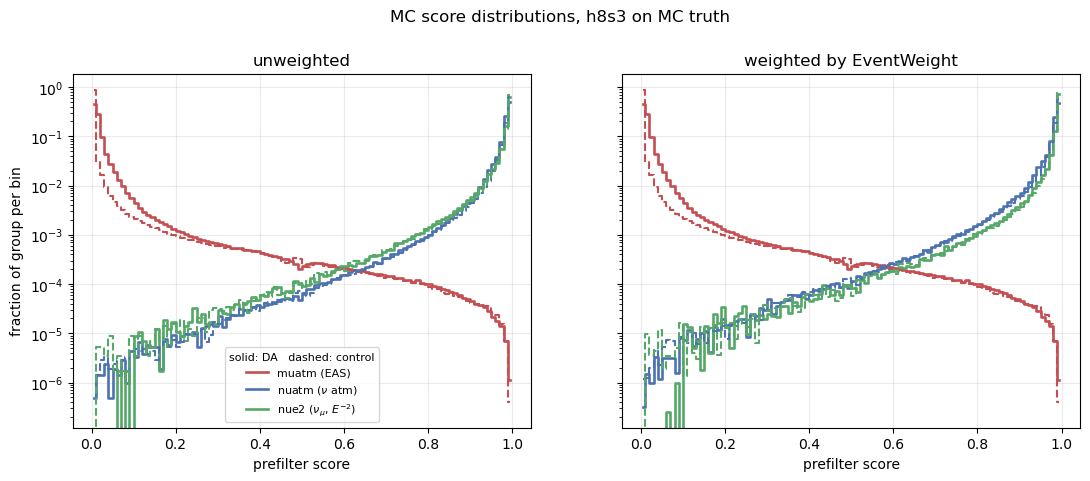

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
centres = 0.5 * (SCORE_EDGES[:-1] + SCORE_EDGES[1:])

for axis, weighted in zip(axes, (False, True)):
    for model, events in mc.items():
        for data_class in GROUP_LABEL:
            subset = events[events.data_class == data_class]
            counts, _ = np.histogram(subset.score, bins=SCORE_EDGES,
                                     weights=event_weights(subset, weighted))
            axis.step(centres, counts / counts.sum(), where="mid",
                      color=GROUP_COLOR[data_class], **MODEL_LINE[model],
                      label=GROUP_LABEL[data_class] if model == list(mc)[0] else None)
    axis.set(yscale="log", xlabel="prefilter score",
             title="weighted by EventWeight" if weighted else "unweighted")
    axis.grid(alpha=0.25)

axes[0].set_ylabel("fraction of group per bin")
axes[0].legend(fontsize=8, title="solid: DA   dashed: control", title_fontsize=8)
figure.suptitle("MC score distributions, h8s3 on MC truth", y=1.02)
save(figure, "01_score_distributions.png")

## 2. Neutrino efficiency and EAS suppression

figures/02_efficiency_suppression_roc.png


,model,weighted,threshold,suppression,nuatm_2020,nue2_2020
0,DA (max_lambda 0.05),False,0.798033,0.001,0.990086,0.985944
1,control (max_lambda 0.0),False,0.791540,0.001,0.991248,0.986961
2,DA (max_lambda 0.05),True,0.798033,0.001,0.982909,0.988312
3,control (max_lambda 0.0),True,0.791540,0.001,0.984434,0.988874


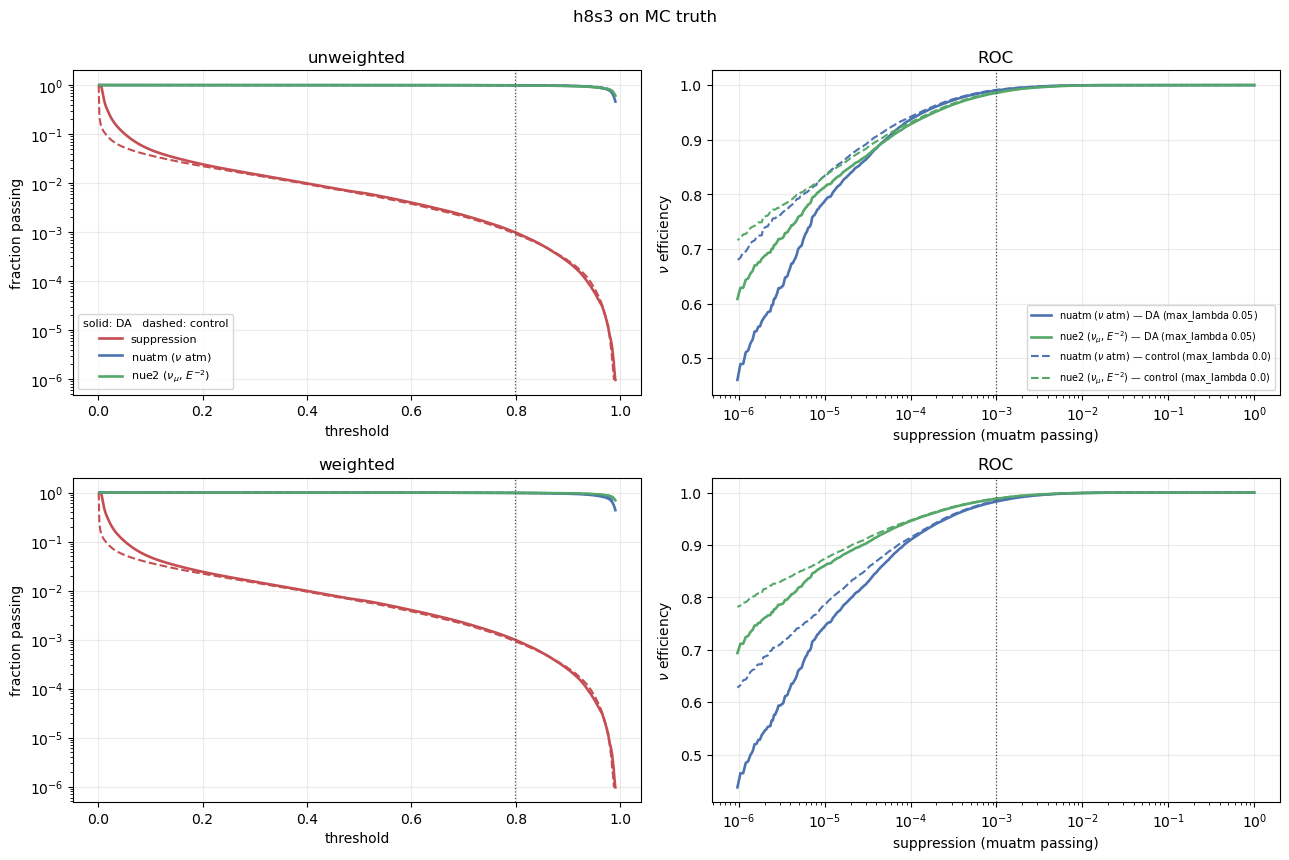

In [6]:
figure, axes = plt.subplots(2, 2, figsize=(13, 8.6))

for row, weighted in enumerate((False, True)):
    versus_threshold, roc = axes[row]
    for model in mc:
        curves = suppression_and_efficiency(ranked[model, weighted])
        versus_threshold.plot(curves.threshold, curves.suppression,
                              color=GROUP_COLOR["muatm_2020"], **MODEL_LINE[model],
                              label="suppression" if model == list(mc)[0] else None)
        for data_class in NEUTRINOS:
            versus_threshold.plot(curves.threshold, curves[data_class],
                                  color=GROUP_COLOR[data_class], **MODEL_LINE[model],
                                  label=GROUP_LABEL[data_class]
                                        if model == list(mc)[0] else None)
            roc.plot(curves.suppression, curves[data_class],
                     color=GROUP_COLOR[data_class], **MODEL_LINE[model],
                     label=f"{GROUP_LABEL[data_class]} — {model}")
    versus_threshold.axvline(working_point(ranked[list(mc)[0], weighted])["threshold"],
                             color="0.3", lw=0.9, ls=":")
    roc.axvline(TARGET_SUPPRESSION, color="0.3", lw=0.9, ls=":")
    versus_threshold.set(yscale="log", xlabel="threshold", ylabel="fraction passing",
                         title="weighted" if weighted else "unweighted")
    roc.set(xscale="log", xlabel="suppression (muatm passing)",
            ylabel=r"$\nu$ efficiency", title="ROC")
    for axis in (versus_threshold, roc):
        axis.grid(alpha=0.25)
    if row == 0:
        versus_threshold.legend(fontsize=8, title="solid: DA   dashed: control",
                                title_fontsize=8)
        roc.legend(fontsize=7, loc="lower right")

figure.suptitle("h8s3 on MC truth", y=0.995)
figure.tight_layout()
save(figure, "02_efficiency_suppression_roc.png")

points = pd.DataFrame([{"model": model, "weighted": weighted,
                        **working_point(ranked[model, weighted])}
                       for weighted in (False, True) for model in mc])
assert (points.suppression <= TARGET_SUPPRESSION).all(), points
points

## 3. Efficiency at suppression 1e-3, vs zenith and vs energy

/tmp/ipykernel_1989244/2865621299.py:90: RuntimeWarning: invalid value encountered in divide
  return np.where(total > 0, chosen / total, np.nan)


figures/03_efficiency_vs_zenith_and_energy.png


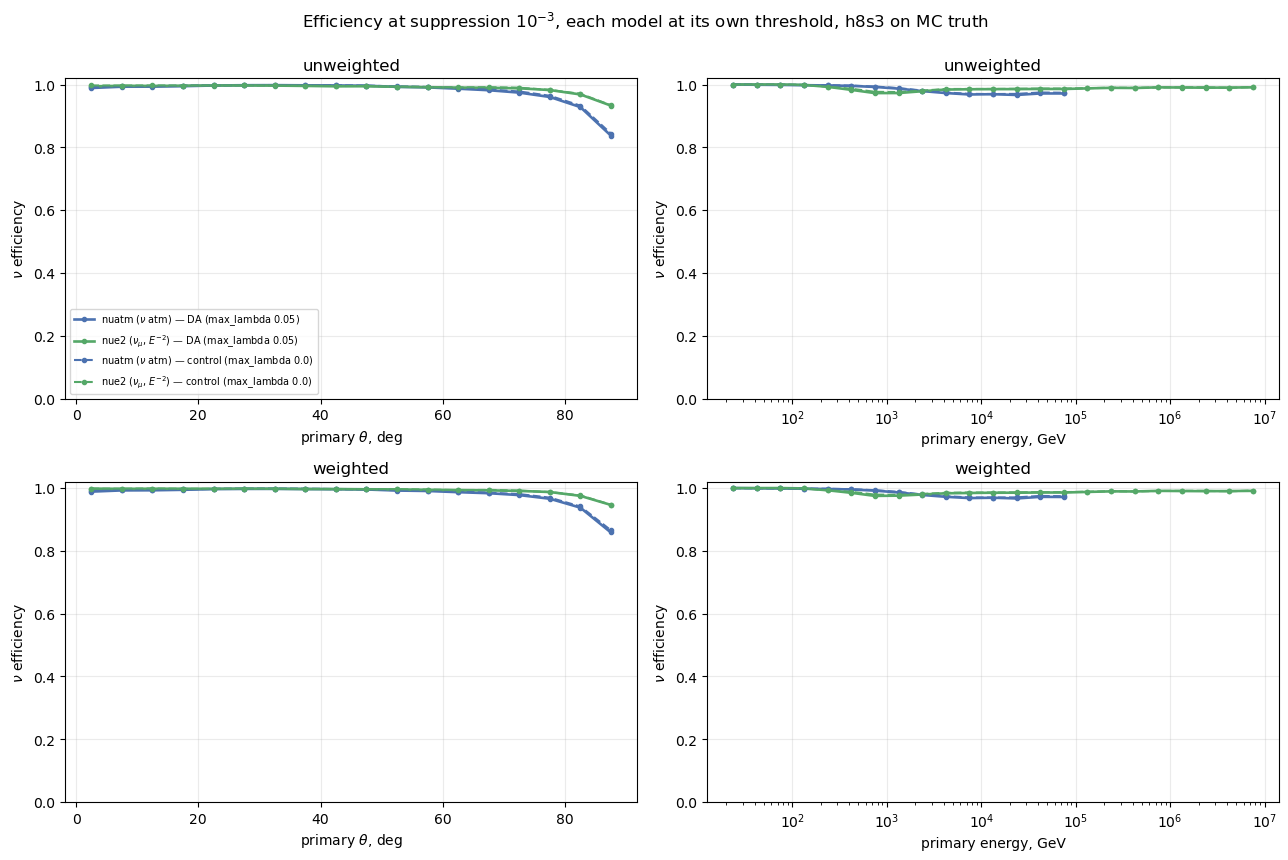

In [7]:
figure, axes = plt.subplots(2, 2, figsize=(13, 8.6))

for row, weighted in enumerate((False, True)):
    for column, (variable, edges, xlabel, log_x) in enumerate((
            ("theta_deg", THETA_EDGES, r"primary $\theta$, deg", False),
            ("energy_gev", ENERGY_EDGES, "primary energy, GeV", True))):
        axis = axes[row, column]
        centres = (np.sqrt(edges[:-1] * edges[1:]) if log_x
                   else 0.5 * (edges[:-1] + edges[1:]))
        for model, events in mc.items():
            threshold = working_point(ranked[model, weighted])["threshold"]
            for data_class in NEUTRINOS:
                axis.plot(centres,
                          efficiency_profile(events, data_class, threshold,
                                             variable, edges, weighted),
                          color=GROUP_COLOR[data_class], **MODEL_LINE[model],
                          marker="o", ms=3,
                          label=f"{GROUP_LABEL[data_class]} — {model}"
                                if row == 0 and column == 0 else None)
        axis.set(xlabel=xlabel, ylabel=r"$\nu$ efficiency", ylim=(0, 1.02),
                 title="weighted" if weighted else "unweighted")
        if log_x:
            axis.set_xscale("log")
        axis.grid(alpha=0.25)
axes[0, 0].legend(fontsize=7, loc="lower left")

figure.suptitle(r"Efficiency at suppression $10^{-3}$, each model at its own threshold, "
                "h8s3 on MC truth", y=0.995)
figure.tight_layout()
save(figure, "03_efficiency_vs_zenith_and_energy.png")

## 4. exp_full over muatm along the score

h8s3 by the sig-noise model on both sides. Each histogram is normalised to its own total,
so the level is a shape ratio and not a rate.

figures/04_experimental_excess.png


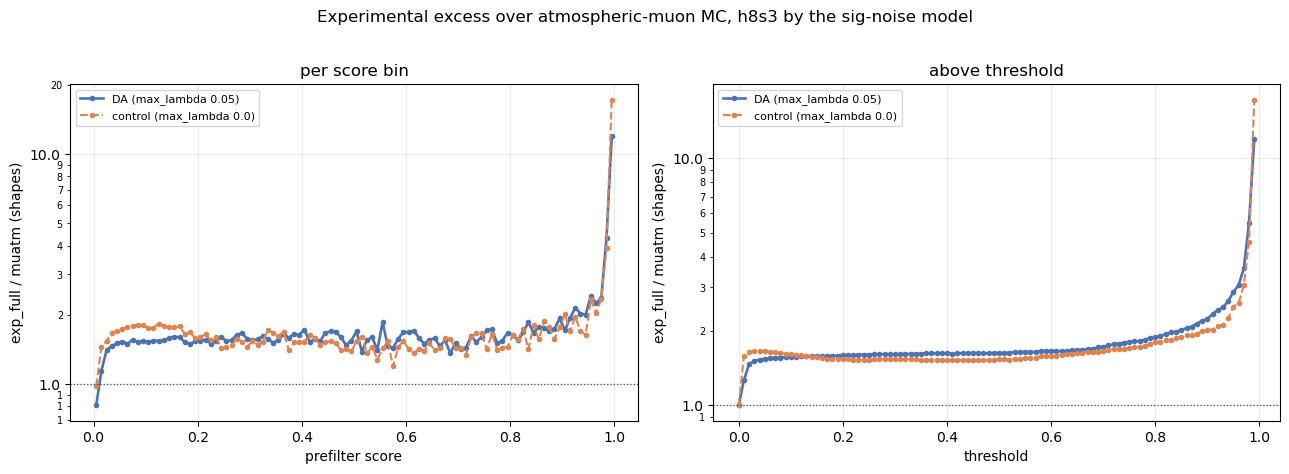

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
centres = 0.5 * (SCORE_EDGES[:-1] + SCORE_EDGES[1:])

for model in CHECKPOINT:
    differential, cumulative = shape_ratio(exp_signoise[model], muatm_signoise[model])
    axes[0].plot(centres, differential, color=MODEL_COLOR[model],
                 **MODEL_LINE[model], marker="o", ms=3, label=model)
    axes[1].plot(SCORE_EDGES[:-1], cumulative, color=MODEL_COLOR[model],
                 **MODEL_LINE[model], marker="o", ms=3, label=model)

for axis, (title, xlabel) in zip(axes, (("per score bin", "prefilter score"),
                                        ("above threshold", "threshold"))):
    axis.axhline(1.0, color="0.3", lw=0.9, ls=":")
    axis.set(yscale="log", xlabel=xlabel, ylabel="exp_full / muatm (shapes)", title=title)
    axis.yaxis.set_major_formatter(ticker.ScalarFormatter())
    axis.yaxis.set_minor_formatter(ticker.ScalarFormatter())
    axis.tick_params(axis="y", which="minor", labelsize=7)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)

figure.suptitle("Experimental excess over atmospheric-muon MC, h8s3 by the sig-noise model",
                y=1.02)
figure.tight_layout()
save(figure, "04_experimental_excess.png")